# 06 - Explicabilidad y negocio

## Objetivo de este cuaderno

Explicamos qué variables pesan más en el precio, validamos las hipótesis y respondemos a las preguntas de negocio.

- **Lee:** el mejor modelo de models/ y test de data/processed/
- **Guarda:** figuras en outputs/

### Importar librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

## 1. Cargar el modelo y los datos de prueba

Cargamos el Random Forest, el modelo elegido en el cuaderno de evaluación, con joblib, y el conjunto de prueba.

In [2]:
rf = joblib.load('../models/random_forest.joblib')

X_test = pd.read_csv('../data/processed/X_test.csv')
y_test = pd.read_csv('../data/processed/y_test.csv')['price']
print(X_test.shape, y_test.shape)

(8123, 26) (8123,)


## 2. ¿Qué variables influyen más en el precio? (pregunta 8)

La importancia de variables del Random Forest dice cuánto pesa cada variable, pero no si sube o baja el precio. Para eso usamos SHAP, que calcula para cada coche cuánto aporta cada variable a su precio estimado, en positivo o en negativo, respecto al precio medio que predice el modelo.

Como el modelo predice el logaritmo del precio, un valor SHAP de 0,10 equivale aproximadamente a un 10 % más de precio, y uno de -0,10 a un 10 % menos.

Calcular SHAP en un Random Forest con 100 árboles sin límite de profundidad es lento, así que usamos una muestra aleatoria de 500 coches del conjunto de prueba. Es suficiente para ver el comportamiento general del modelo.

In [3]:
muestra = X_test.sample(500, random_state=42)

shap.TreeExplainer prepara el cálculo para modelos de árboles y shap_values devuelve una tabla con un valor por coche y por variable. Esta celda tarda un par de minutos.

In [4]:
explicador = shap.TreeExplainer(rf)
valores_shap = explicador.shap_values(muestra)
valores_shap.shape

(500, 26)

Primero vemos la importancia media de cada variable: la media del valor SHAP en valor absoluto, sin tener en cuenta si sube o baja el precio.

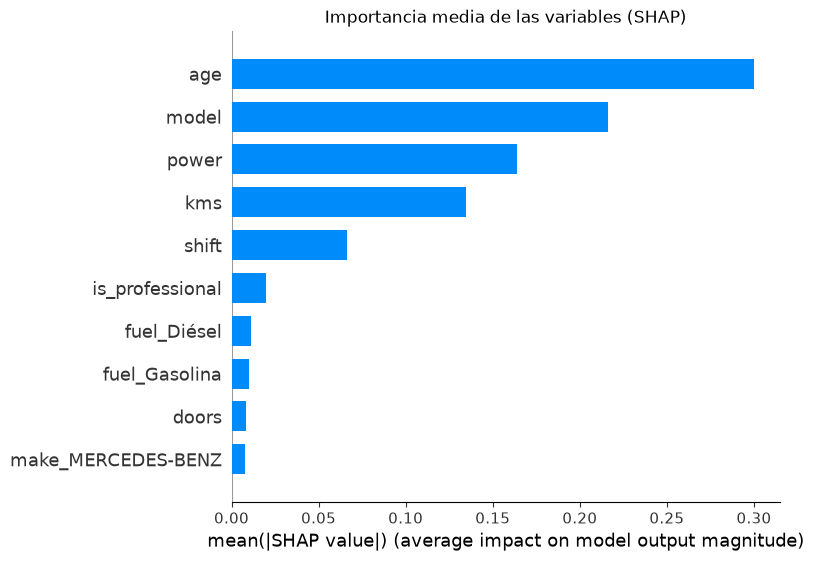

In [5]:
shap.summary_plot(valores_shap, muestra, plot_type='bar', max_display=10, show=False)
plt.title('Importancia media de las variables (SHAP)')
plt.savefig('../outputs/figures/18_shap_importancia.png', bbox_inches='tight')
plt.show()

Después vemos la dirección. En este gráfico cada punto es un coche. El color indica si el valor de la variable es alto (rojo) o bajo (azul), y la posición horizontal si esa variable sube el precio (derecha) o lo baja (izquierda).

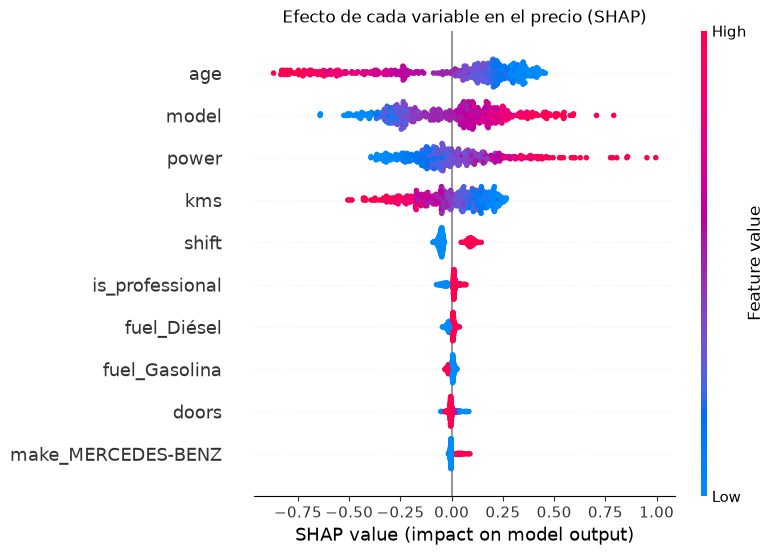

In [6]:
shap.summary_plot(valores_shap, muestra, max_display=10, show=False)
plt.title('Efecto de cada variable en el precio (SHAP)')
plt.savefig('../outputs/figures/19_shap_efecto.png', bbox_inches='tight')
plt.show()

### Observaciones de SHAP

- La antigüedad (age) es la variable que más influye en el precio. Los coches más viejos (rojo) bajan el precio, en algunos casos más de un 50 %, y los más nuevos (azul) lo suben.
- La segunda es el modelo del coche. Los modelos con precio medio alto (rojo) suben el precio estimado y los más baratos lo bajan. Es la variable que codificamos con TargetEncoder, así que resume el valor de mercado de cada modelo.
- La potencia (power) sube el precio cuando es alta, y en los coches más potentes llega a aportar mucho.
- Los kilómetros (kms) funcionan al revés: muchos kilómetros bajan el precio y pocos lo suben.
- El cambio automático (shift = 1) sube el precio de forma clara, alrededor de un 10 %, y el manual lo baja.
- El resto de variables, como el tipo de vendedor, el combustible, las puertas o la marca, pesan muy poco una vez que el modelo ya conoce el modelo del coche, su edad, su potencia y sus kilómetros.
- El orden coincide con la importancia de variables del Random Forest en el cuaderno de modelado: age, model, power y kms.

## 3. Validación de las hipótesis con el modelo

En el EDA comprobamos las hipótesis con medianas de los datos. Ahora las comprobamos con el modelo mediante una simulación: tomamos los coches de prueba, les cambiamos solo una variable (la antigüedad o el combustible) y vemos cómo cambia el precio que estima el modelo. Así comparamos coches idénticos en todo lo demás, algo que con los datos en bruto no se puede hacer.

### H1 y H2: depreciación por marca

Para cada coche de prueba simulamos dos versiones: una con 2 años y otra con 8 años. Hacemos copias de X_test con copy para no modificar los datos originales.

In [7]:
coches_2 = X_test.copy()
coches_2['age'] = 2

coches_8 = X_test.copy()
coches_8['age'] = 8

In [8]:
simulacion = pd.DataFrame()
simulacion['precio_2_anios'] = np.exp(rf.predict(coches_2))
simulacion['precio_8_anios'] = np.exp(rf.predict(coches_8))

Recuperamos la marca de cada coche a partir de las columnas make_. idxmax(axis=1) devuelve, en cada fila, el nombre de la columna con el valor más alto, que es la que vale 1. Después quitamos el prefijo make_ con str.replace.

In [9]:
columnas_marca = [c for c in X_test.columns if c.startswith('make_')]
simulacion['marca'] = X_test[columnas_marca].idxmax(axis=1).str.replace('make_', '')
simulacion.head()

,precio_2_anios,precio_8_anios,marca
0,8664.205648,5427.866961,OPEL
1,32042.370499,25794.393159,VOLKSWAGEN
2,31302.764644,23973.664979,Other
3,17914.808803,12478.420373,Other
4,12746.884910,10772.104024,SEAT


Calculamos el valor retenido de cada marca: el precio medio a los 8 años en porcentaje del precio medio a los 2 años.

In [10]:
retencion = simulacion.groupby('marca')[['precio_2_anios', 'precio_8_anios']].mean()
retencion['valor_retenido (%)'] = retencion['precio_8_anios'] / retencion['precio_2_anios'] * 100
retencion = retencion.sort_values('valor_retenido (%)', ascending=False)
retencion.round(1)

,precio_2_anios,precio_8_anios,valor_retenido (%)
marca,,,
MERCEDES-BENZ,32911.1,24221.5,73.6
Other,21201.1,15495.7,73.1
VOLKSWAGEN,18491.8,13431.6,72.6
SEAT,14513.5,10224.6,70.4
AUDI,27100.5,18960.2,70.0
BMW,27766.5,19358.8,69.7
CITROEN,13890.9,9677.7,69.7
OPEL,14135.4,9717.8,68.7
RENAULT,13744.3,9230.3,67.2


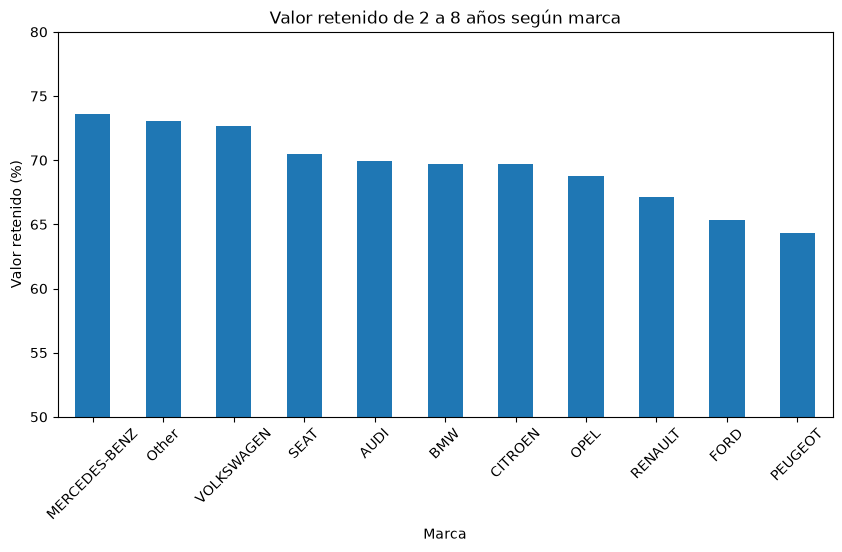

In [11]:
retencion['valor_retenido (%)'].plot(kind='bar', figsize=(10, 5))
plt.title('Valor retenido de 2 a 8 años según marca')
plt.xlabel('Marca')
plt.ylabel('Valor retenido (%)')
plt.ylim(50, 80)
plt.xticks(rotation=45)
plt.savefig('../outputs/figures/20_valor_retenido_marca.png', bbox_inches='tight')
plt.show()

Para H1 comparamos las marcas de alta gama (Audi, BMW y Mercedes-Benz) con el resto.

In [12]:
alta_gama = simulacion['marca'].isin(['AUDI', 'BMW', 'MERCEDES-BENZ'])

retenido_alta = simulacion[alta_gama]['precio_8_anios'].mean() / simulacion[alta_gama]['precio_2_anios'].mean() * 100
retenido_resto = simulacion[~alta_gama]['precio_8_anios'].mean() / simulacion[~alta_gama]['precio_2_anios'].mean() * 100

print('Valor retenido alta gama:', round(retenido_alta, 1), '%')
print('Valor retenido resto de marcas:', round(retenido_resto, 1), '%')

Valor retenido alta gama: 71.2 %
Valor retenido resto de marcas: 70.8 %


### H3: precio según el combustible

Simulamos los mismos coches de prueba con tres combustibles distintos. Ponemos a 0 todas las columnas fuel_ y a 1 solo la del combustible que queremos probar.

In [13]:
columnas_fuel = [c for c in X_test.columns if c.startswith('fuel_')]

coches_electrico = X_test.copy()
coches_electrico[columnas_fuel] = 0
coches_electrico['fuel_Eléctrico'] = 1

coches_diesel = X_test.copy()
coches_diesel[columnas_fuel] = 0
coches_diesel['fuel_Diésel'] = 1

coches_gasolina = X_test.copy()
coches_gasolina[columnas_fuel] = 0
coches_gasolina['fuel_Gasolina'] = 1

In [14]:
print('Precio medio como eléctrico:', round(np.exp(rf.predict(coches_electrico)).mean()), '€')
print('Precio medio como diésel:', round(np.exp(rf.predict(coches_diesel)).mean()), '€')
print('Precio medio como gasolina:', round(np.exp(rf.predict(coches_gasolina)).mean()), '€')

Precio medio como eléctrico: 16646 €


Precio medio como diésel: 17288 €


Precio medio como gasolina: 16265 €


### Observaciones de las hipótesis

- H1 (los coches de alta gama se deprecian más rápido): refutada. Según el modelo, Audi, BMW y Mercedes-Benz retienen de 2 a 8 años un 71,2 % de su valor y el resto de marcas un 70,8 %, prácticamente lo mismo. Mercedes-Benz es incluso la marca que más valor retiene (74 %). Coincide con lo que vimos en el EDA.
- H2 (hay marcas que se deprecian menos que otras): apoyada. El valor retenido va del 64 % de Peugeot al 74 % de Mercedes-Benz, diez puntos de diferencia en coches por lo demás idénticos.
- H3 (eléctrico > diésel > gasolina): solo apoyada en parte. El modelo da diésel (17.288 €) > eléctrico (16.646 €) > gasolina (16.265 €). Las diferencias son pequeñas, porque el combustible apenas pesa en el modelo, como vimos con SHAP. Gran parte del efecto del combustible ya lo recoge la variable model: un modelo eléctrico tiene un precio medio alto por sí mismo. Además, en los datos hay muy pocos eléctricos, así que el modelo aprende poco de esa columna. En el EDA el orden sí se cumplía, porque allí comparábamos los coches tal como son y no la misma versión con distinto combustible.

## 4. Preguntas de negocio sobre el margen

La oferta al vendedor es: oferta = precio estimado × (1 − margen) − costes de preparación.

No tenemos datos de costes de preparación, así que los dejamos fuera y nos centramos en el margen. Consideramos que no perdemos dinero en un coche si la oferta es igual o menor que su precio real de mercado, que es el precio al que lo podríamos vender.

In [15]:
precio_real = np.exp(y_test)
precio_estimado = np.exp(rf.predict(X_test))

### Pregunta 11: con un margen fijo, ¿en qué % de coches no perderíamos dinero?

Calculamos la oferta con un margen del 15 % y contamos en cuántos coches queda por debajo del precio real.

In [16]:
margen = 0.15
oferta = precio_estimado * (1 - margen)
sin_perdida = oferta <= precio_real
print('Coches sin pérdida con un margen del 15 %:', round(sin_perdida.mean() * 100, 1), '%')

Coches sin pérdida con un margen del 15 %: 88.3 %


Repetimos el cálculo con varios márgenes para ver cómo cambia.

In [17]:
margenes = [0.05, 0.10, 0.15, 0.20, 0.25]
resultados = []

for m in margenes:
    oferta_m = precio_estimado * (1 - m)
    porcentaje = (oferta_m <= precio_real).mean() * 100
    resultados.append(porcentaje)

tabla_margenes = pd.DataFrame({'margen (%)': [m * 100 for m in margenes], 'coches sin pérdida (%)': resultados})
tabla_margenes.round(1)

,margen (%),coches sin pérdida (%)
0,5.0,67.4
1,10.0,80.1
2,15.0,88.3
3,20.0,93.0
4,25.0,95.6


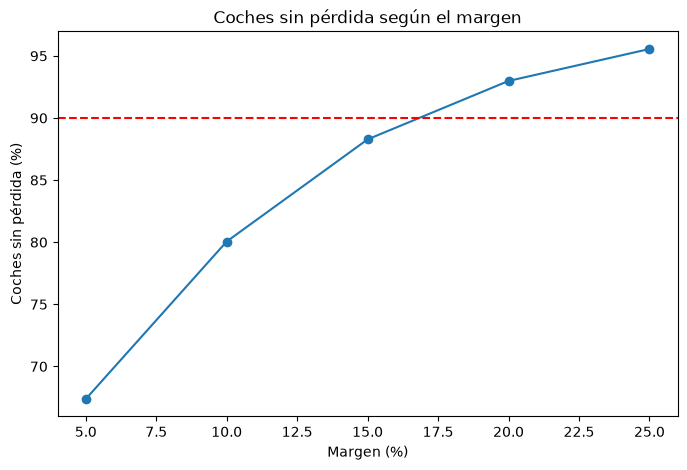

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(tabla_margenes['margen (%)'], tabla_margenes['coches sin pérdida (%)'], marker='o')
plt.axhline(90, color='red', linestyle='--')
plt.title('Coches sin pérdida según el margen')
plt.xlabel('Margen (%)')
plt.ylabel('Coches sin pérdida (%)')
plt.savefig('../outputs/figures/21_coches_sin_perdida_por_margen.png', bbox_inches='tight')
plt.show()

### Pregunta 13: ¿qué margen mínimo hace la oferta segura en el 90 % de los casos?

Para cada coche calculamos el margen mínimo que habría hecho falta para no perder dinero: 1 − precio real / precio estimado. Si el modelo infravalora el coche, sale negativo y cualquier margen sirve.

Después buscamos el margen que cubre al 90 % de los coches con np.percentile, que devuelve el valor por debajo del cual queda el porcentaje de datos que le pidamos.

In [19]:
margen_necesario = 1 - precio_real / precio_estimado
margen_90 = np.percentile(margen_necesario, 90)
print('Margen mínimo para no perder en el 90 % de los coches:', round(margen_90 * 100, 1), '%')

Margen mínimo para no perder en el 90 % de los coches: 16.5 %


Para ver si ese margen espantaría al cliente, comparamos la oferta resultante con el precio real del coche.

In [20]:
oferta_90 = precio_estimado * (1 - margen_90)
print('Oferta mediana respecto al precio real:', round(np.median(oferta_90 / precio_real) * 100, 1), '%')

Oferta mediana respecto al precio real: 83.4 %


### Observaciones de las preguntas de negocio

- Pregunta 11: con un margen del 15 %, no perderíamos dinero en el 88,3 % de los coches. Con un 10 % baja al 80,1 % y con un 20 % sube al 93 %.
- Pregunta 13: el margen mínimo para no perder en el 90 % de los coches es del 16,5 %, muy cerca del 15 % que planteamos al principio.
- Con ese margen, la oferta mediana queda en un 83,4 % del precio real del coche. Es decir, al vendedor típico le ofreceríamos unos 17 € menos por cada 100 € de lo que vale su coche, una rebaja razonable para un concesionario que asume la venta, la garantía y los costes.
- El 10 % de coches restante es donde el modelo sobrevalora mucho. Por lo visto en el cuaderno de evaluación, es de esperar que sean sobre todo coches baratos y antiguos, que son los que conviene que revise una persona antes de hacer la oferta.
- Estos cálculos no incluyen los costes de preparación, que reducirían la oferta un poco más.